Time Series 
---
1. Decomposition 
2. Centered Moving Average / Rolling Mean
3. Trailing Rolling Mean
4. Simple Exponential Method
5. Holt's Linear Trend
6. Holt's Exponential Trend
7. Additive Damp Trend
8. Holt Winters Additive Method
9. Holt Winters Multiplicative Method

base kernel

In [1]:
import pandas as pd
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose # pip install statsmodels
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
import os
os.chdir("C:/Users/dbda.STUDENTSDC/Desktop/Practical Machine Learning/Datasets")

In [2]:
df = pd.read_csv("FRED-NROUST.csv")
df

,Date,Value
0,01-01-1949,5.255053
1,01-04-1949,5.261516
2,01-07-1949,5.268013
3,01-10-1949,5.274564
4,01-01-1950,5.281182
...,...,...
291,01-10-2021,4.450651
292,01-01-2022,4.445137
293,01-04-2022,4.440214
294,01-07-2022,4.435784


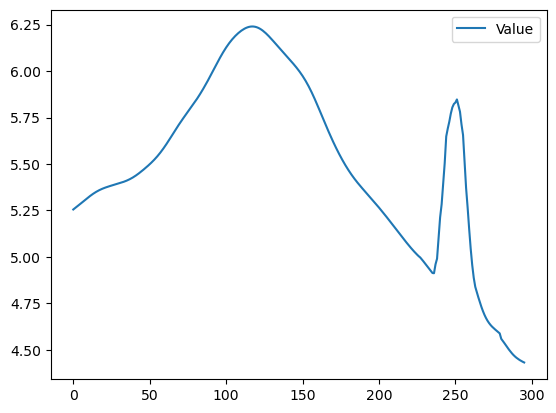

In [3]:
df.plot()
plt.show()

Decomposition
-

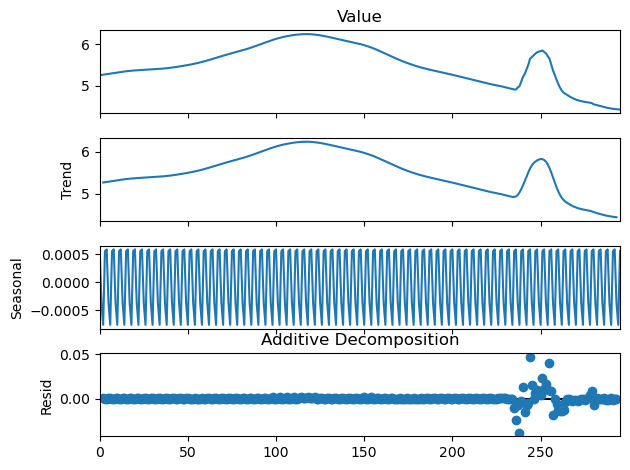

In [4]:
series = df['Value']

# 2. Perform Decomposition 'additive'
result = seasonal_decompose(series, model='additive',period=4) # period =4 , bez we have data quaterly
result.plot()
plt.title("Additive Decomposition")
plt.show()

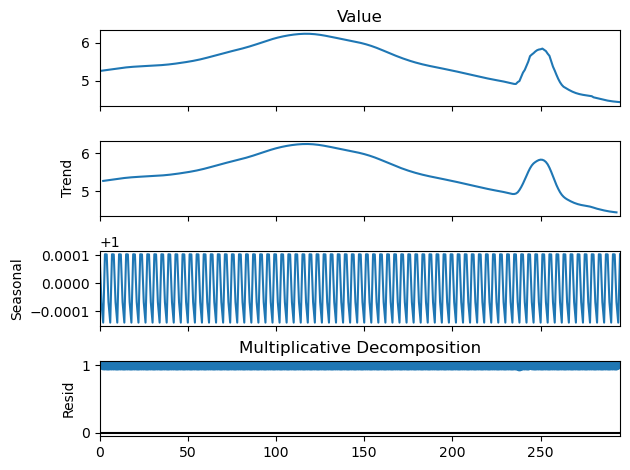

In [5]:
# 2. Perform Decomposition 'multiplicative'
result = seasonal_decompose(series, model='multiplicative',period=4)
result.plot()
plt.title("Multiplicative Decomposition")
plt.show()

Centered Moving Average / Rolling Mean
--

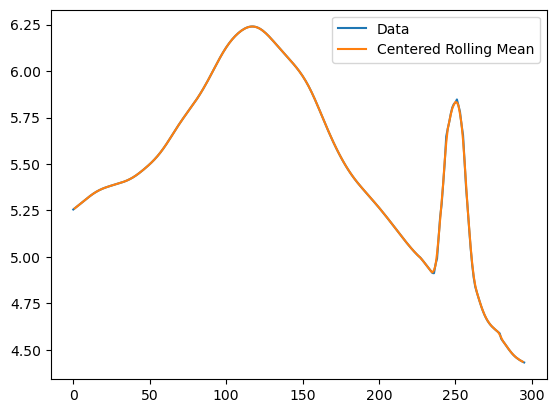

In [6]:
span = 3 # span increased -> smoothening increased
fcast = df['Value'].rolling(span,center=True).mean()
plt.plot(df['Value'],label='Data')
plt.plot(fcast, label='Centered Rolling Mean')
plt.legend(loc='best')
plt.show()

Trailing Rolling Mean
--

Train Test split

In [7]:
y_train = df['Value'][:-8] # everything except the last 8 observations.
y_test = df['Value'][-8:] # last 8 observations

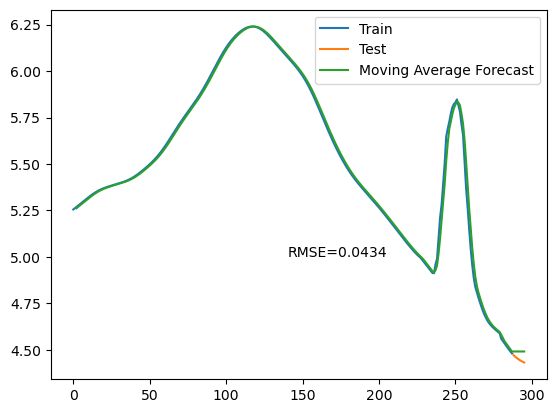

In [8]:
span = 3 # Time window
fcast = y_train.rolling(span).mean()
MA = fcast.iloc[-1]
MA_series = pd.Series(MA.repeat(len(y_test)))
MA_fcast = pd.concat([fcast,MA_series],ignore_index=True)
plt.plot(y_train, label='Train')
plt.plot(y_test,label='Test')
plt.plot(MA_fcast,label='Moving Average Forecast')
rms = np.round(root_mean_squared_error(y_test, MA_series),4)
plt.text(140,5, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

.. Span Size   |     Effect on Model,       |      RMSE Outcome

1. Too Small   |    Overfits to noise,      |       High RMSE (Model is too jumpy)
2. Sweet Spot  |  Balances noise & trend    |       Lowest RMSE
3. Too Large   |     Too much lag           |   High RMSE (Model is too slow to react)

## Simple Exponential Method

In [9]:
from statsmodels.tsa.api import SimpleExpSmoothing

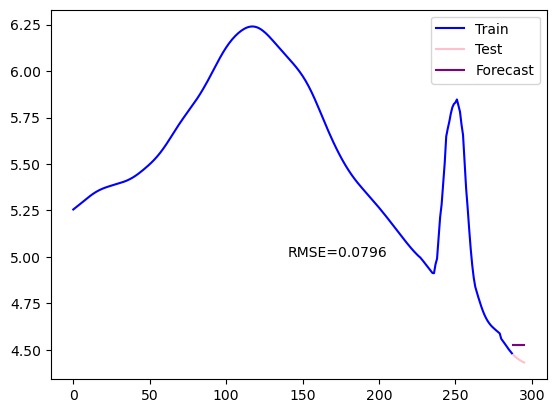

In [10]:
alpha = 0.2
ses_model = SimpleExpSmoothing(y_train).fit(smoothing_level=alpha,optimized=False)
fcast1 = ses_model.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),4)
plt.text(140,5, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters & optimized =True

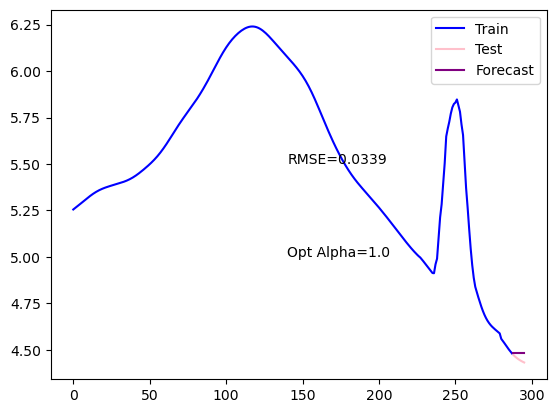

In [11]:
ses_model = SimpleExpSmoothing(y_train).fit(optimized=True)
fcast1 = ses_model.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),4)
opt_alpha = np.round(ses_model.model.params['smoothing_level'],2)
plt.text(140,5,f"Opt Alpha={opt_alpha}")
plt.text(140,5.5, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Holt's Linear Trend
-

In [12]:
from statsmodels.tsa.api import Holt

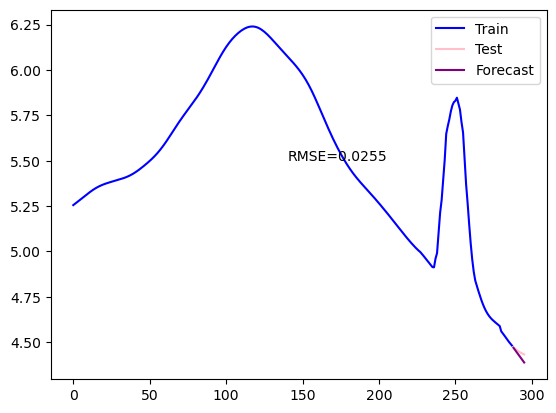

In [13]:
alpha, beta = 0.4,0.2
holt = Holt(y_train)
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),4)
plt.text(140,5.5, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

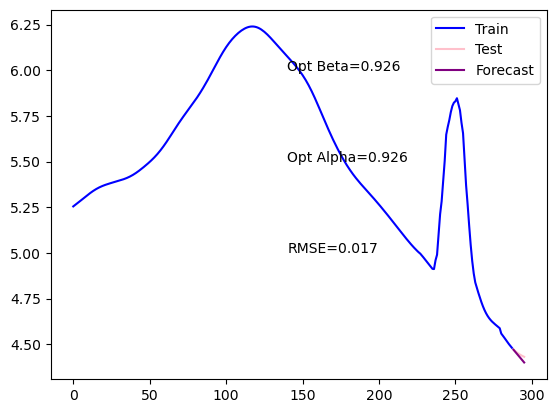

In [24]:
holt = Holt(y_train)
fit1 = holt.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),4)
plt.text(140,5, f"RMSE={rms}")
plt.text(140,5.5,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 4)}")
plt.text(140,6,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 4)}")
plt.legend(loc='best')
plt.show()

Holt's Exponential Trend
--

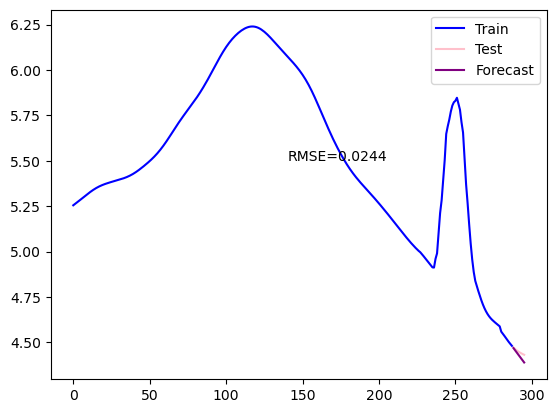

In [15]:
alpha, beta = 0.4,0.2
holt = Holt(y_train,exponential=True)
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),4)
plt.text(140,5.5, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

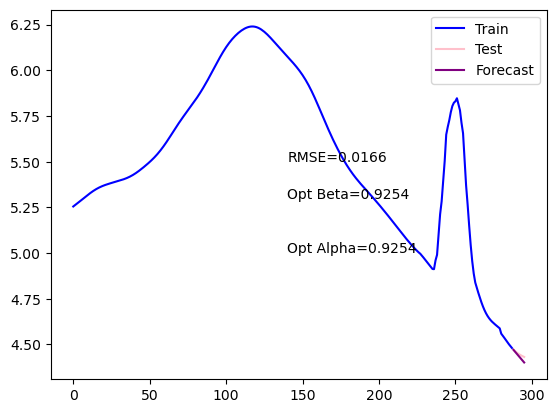

In [16]:
holt = Holt(y_train,exponential=True)
fit1 = holt.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),4)
plt.text(140,5,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 4)}")
plt.text(140,5.3,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 4)}")
plt.text(140,5.5, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Additive Damp Trend
-

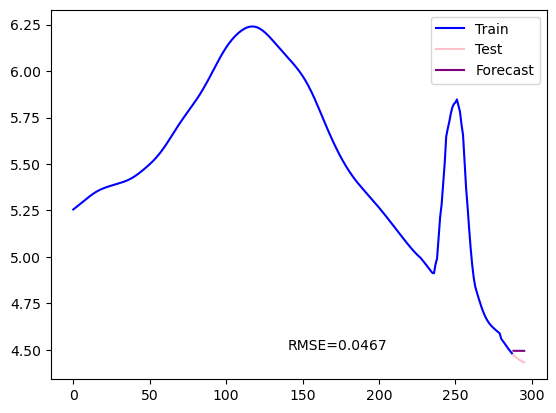

In [17]:
alpha, beta,phi = 0.4,0.2,0.3
holt = Holt(y_train,damped_trend=True)
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,damping_trend=phi,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),4)
plt.text(140,4.5, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

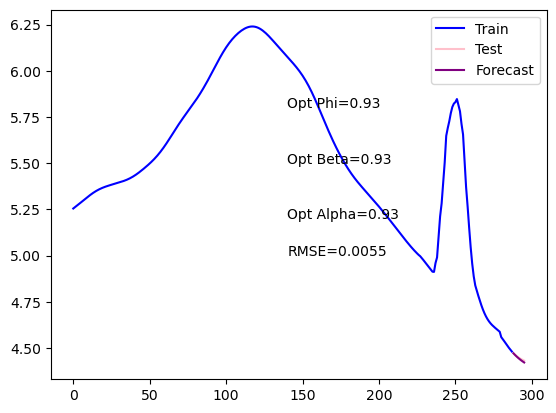

In [18]:
holt = Holt(y_train,damped_trend=True)
fit1 = holt.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),4)
plt.text(140,5, f"RMSE={rms}")
plt.text(140,5.2,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 2)}")
plt.text(140,5.5,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 2)}")
plt.text(140,5.8,f"Opt Phi={np.round(fit1.params['damping_trend'], 2)}")
plt.legend(loc='best')
plt.show()

Till above we saw that forecast doesn't match with out train & test. So to match it we will do Exponential Smoothing

Holt Winters Additive Method
-

In [19]:
from statsmodels.tsa.api import ExponentialSmoothing

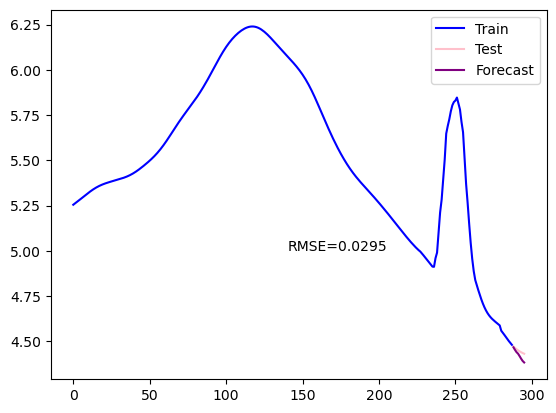

In [20]:
alpa,beta,gamma=0.8,0.02,0.1
hw_add = ExponentialSmoothing(y_train,seasonal_periods=4,trend='add', seasonal='add')
fit1 =hw_add.fit(smoothing_level=alpha,smoothing_trend=beta,smoothing_seasonal=gamma)
fcast1 =fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),4)
plt.text(140,5, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

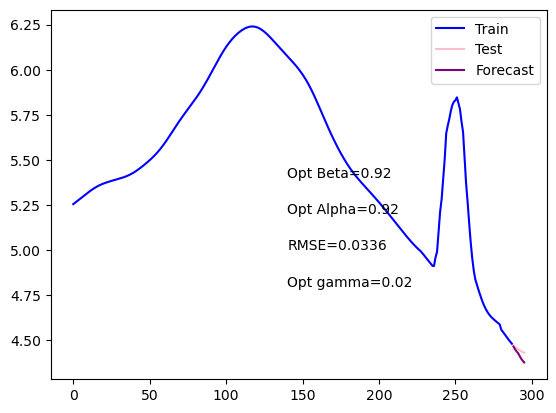

In [25]:
hw_add = ExponentialSmoothing(y_train,seasonal_periods=4,trend='add', seasonal='add')
fit1 =hw_add.fit(optimized=True)
fcast1 =fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),4)
plt.text(140,5, f"RMSE={rms}")
plt.text(140,5.2,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 2)}")
plt.text(140,5.4,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 2)}")
plt.text(140,4.8,f"Opt gamma={np.round(fit1.params['smoothing_seasonal'], 2)}")
plt.legend(loc='best')
plt.show()

Holt Winters Multiplicative Method
-

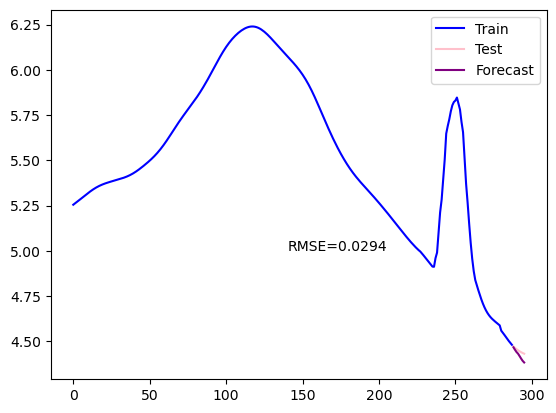

In [22]:
alpa,beta,gamma=0.8,0.02,0.1
hw_add = ExponentialSmoothing(y_train,seasonal_periods=4,trend='add', seasonal='mul')
fit1 =hw_add.fit(smoothing_level=alpha,smoothing_trend=beta,smoothing_seasonal=gamma)
fcast1 =fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),4)
plt.text(140,5, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

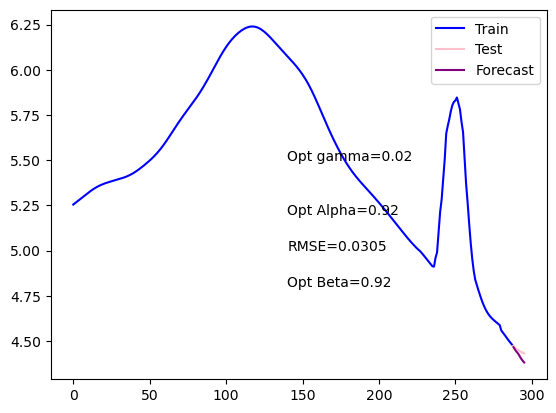

In [23]:
hw_add = ExponentialSmoothing(y_train,seasonal_periods=4,trend='add', seasonal='mul')
fit1 =hw_add.fit(optimized=True)
fcast1 =fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),4)
plt.text(140,5, f"RMSE={rms}")
plt.text(140,5.2,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 2)}")
plt.text(140,4.8,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 2)}")
plt.text(140,5.5,f"Opt gamma={np.round(fit1.params['smoothing_seasonal'], 2)}")
plt.legend(loc='best')
plt.show()